Import libraries

In [11]:
# ==========================================
# TASK 2: REAL ESTATE HOUSING PRICE PREDICTION
# Datheon Machine Learning Internship
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


Load the official dataset

In [12]:
import os
import urllib.request

# Official California Housing dataset
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

# Create data folder if it doesn't exist
os.makedirs("data", exist_ok=True)

# Download the dataset
urllib.request.urlretrieve(
    url,
    "data/housing.csv"
)

# Check downloaded file
print("Dataset downloaded successfully!")

print("File size:", os.path.getsize("data/housing.csv"), "bytes")

Dataset downloaded successfully!
File size: 1423529 bytes


In [13]:
import pandas as pd

df = pd.read_csv("data/housing.csv")

print("Dataset loaded successfully!")

print("\nDataset shape:")
print(df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!

Dataset shape:
(20640, 10)

First five rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


Exploratory Data Analysis

STATISTICAL SUMMARY


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


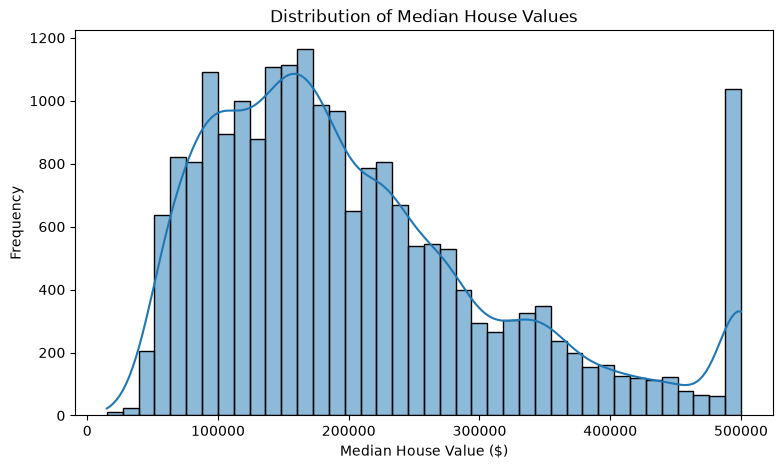

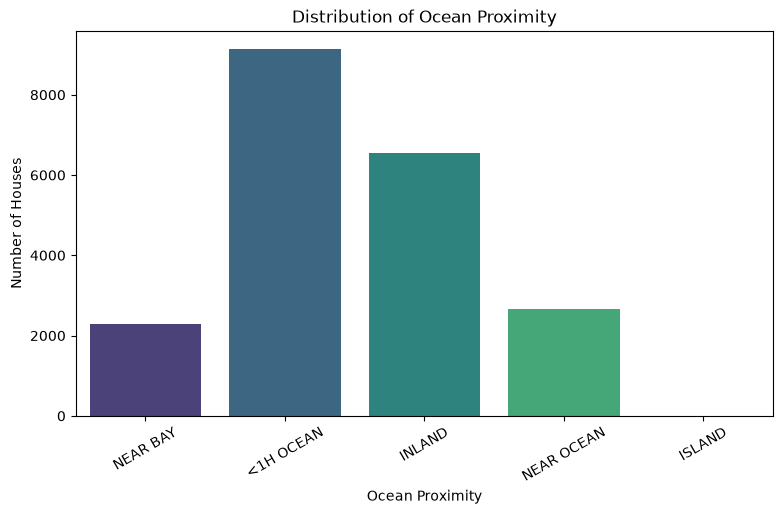

In [14]:
# Statistical summary

print("STATISTICAL SUMMARY")

display(df.describe())

# Distribution of median house values

plt.figure(figsize=(9, 5))

sns.histplot(
    df["median_house_value"],
    bins=40,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")

plt.show()


# Distribution of ocean proximity

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="ocean_proximity",
    hue="ocean_proximity",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Houses")

plt.xticks(rotation=30)

plt.show()

Missing-value analysis

MISSING VALUE REPORT


,Missing Values,Missing Percentage
longitude,0,0.000000
latitude,0,0.000000
housing_median_age,0,0.000000
total_rooms,0,0.000000
total_bedrooms,207,1.002907
population,0,0.000000
households,0,0.000000
median_income,0,0.000000
median_house_value,0,0.000000
ocean_proximity,0,0.000000


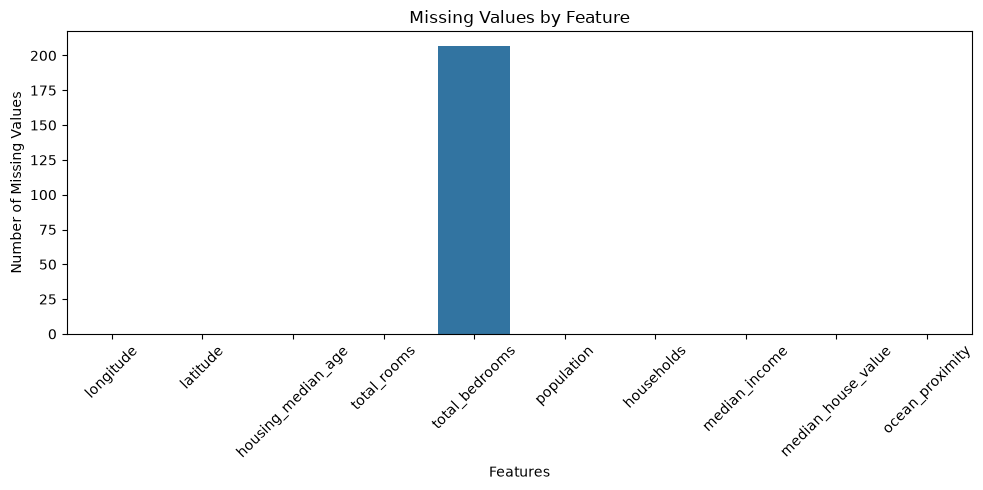

In [15]:
# Calculate missing values

missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

print("MISSING VALUE REPORT")

display(missing_report)

# Visualize missing values

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_report.index,
    y=missing_report["Missing Values"]
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Feature engineering

In [16]:
# Create a copy of the dataset

df = df.copy()

# Average rooms per household

df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

# Average bedrooms per room

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

# Average population per household

df["population_per_household"] = (
    df["population"] / df["households"]
)

# Interaction feature: income multiplied by rooms per household

df["income_x_rooms"] = (
    df["median_income"] * df["rooms_per_household"]
)

# Display the new features

print("NEW ENGINEERED FEATURES")

display(
    df[
        [
            "rooms_per_household",
            "bedrooms_per_room",
            "population_per_household",
            "income_x_rooms"
        ]
    ].head()
)

print("\nUpdated dataset shape:", df.shape)

NEW ENGINEERED FEATURES


,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms
0,6.984127,0.146591,2.555556,58.144254
1,6.238137,0.155797,2.109842,51.785271
2,8.288136,0.129516,2.802260,60.150315
3,5.817352,0.184458,2.547945,32.827897
4,6.281853,0.172096,2.181467,24.161264



Updated dataset shape: (20640, 14)


Correlation and multicollinearity analysis

# Select numerical columns

numeric_df = df.select_dtypes(include=np.number)

# Correlation matrix

correlation_matrix = numeric_df.corr()

# Display heatmap

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.show()


# Identify highly correlated feature pairs

feature_correlation = (
    correlation_matrix
    .drop(index="median_house_value")
    .drop(columns="median_house_value")
)

print("HIGHLY CORRELATED FEATURE PAIRS")

for i in range(len(feature_correlation.columns)):
    for j in range(i + 1, len(feature_correlation.columns)):

        value = feature_correlation.iloc[i, j]

        if abs(value) > 0.80:
            print(
                feature_correlation.columns[i],
                "and",
                feature_correlation.columns[j],
                ":",
                round(value, 3)
            )

In [17]:
# Select numerical columns for VIF analysis
numeric_df = df.select_dtypes(include=["number"]).copy()

# Impute missing values for VIF analysis

vif_data = numeric_df.drop(
    columns=["median_house_value"]
).copy()

vif_data = vif_data.fillna(
    vif_data.median()
)

# Calculate VIF

vif_results = pd.DataFrame()

vif_results["Feature"] = vif_data.columns

vif_results["VIF"] = [
    variance_inflation_factor(
        vif_data.values,
        i
    )
    for i in range(vif_data.shape[1])
]

vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

print("VARIANCE INFLATION FACTOR (VIF)")

display(vif_results.round(2))

VARIANCE INFLATION FACTOR (VIF)


,Feature,VIF
6,households,34.07
4,total_bedrooms,33.87
11,income_x_rooms,18.21
3,total_rooms,17.26
7,median_income,13.05
1,latitude,9.50
0,longitude,9.17
5,population,6.71
8,rooms_per_household,5.41
9,bedrooms_per_room,2.75


Separate features and target

In [18]:
# Target variable

y = df["median_house_value"]

# Input features

X = df.drop(
    columns=["median_house_value"]
)

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

# Split data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nData splitting completed!")

Numerical features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms']

Categorical features:
['ocean_proximity']

Training samples: 16512
Testing samples: 4128

Data splitting completed!


Data preprocessing

In [19]:
# Numerical preprocessing

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])


# Combine both preprocessing pipelines

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Train Ordinary Least Squares (OLS)

In [20]:
# Create OLS pipeline

ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model

ols_model.fit(X_train, y_train)

# Make predictions

ols_predictions = ols_model.predict(X_test)

print("OLS model trained successfully!")

OLS model trained successfully!


Train Ridge Regression with GridSearchCV

In [21]:
# Create Ridge pipeline

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# Define alpha values

ridge_parameters = {
    "regressor__alpha": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

# Grid Search

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_parameters,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Train and optimize

ridge_search.fit(X_train, y_train)

# Best model

ridge_model = ridge_search.best_estimator_

# Predictions

ridge_predictions = ridge_model.predict(X_test)

print("Ridge Regression completed!")

print("\nBest Ridge parameters:")
print(ridge_search.best_params_)

Ridge Regression completed!

Best Ridge parameters:
{'regressor__alpha': 1}


Train Lasso Regression with GridSearchCV

In [22]:
# Create Lasso pipeline

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=20000))
])

# Define alpha values

lasso_parameters = {
    "regressor__alpha": [
        0.001,
        0.01,
        0.1,
        1,
        10
    ]
}

# Grid Search

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_parameters,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Train and optimize

lasso_search.fit(X_train, y_train)

# Best model

lasso_model = lasso_search.best_estimator_

# Predictions

lasso_predictions = lasso_model.predict(X_test)

print("Lasso Regression completed!")

print("\nBest Lasso parameters:")
print(lasso_search.best_params_)

Lasso Regression completed!

Best Lasso parameters:
{'regressor__alpha': 1}


Evaluate and compare all models

In [23]:
# Evaluation function

def evaluate_model(name, actual, predictions):

    mae = mean_absolute_error(
        actual,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predictions
        )
    )

    r2 = r2_score(
        actual,
        predictions
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# Evaluate models

results = []

results.append(
    evaluate_model(
        "OLS (Linear Regression)",
        y_test,
        ols_predictions
    )
)

results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        ridge_predictions
    )
)

results.append(
    evaluate_model(
        "Lasso Regression",
        y_test,
        lasso_predictions
    )
)


# Comparison table

results_df = pd.DataFrame(results)

print("FINAL MODEL COMPARISON")

display(results_df.round(4))

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2
0,OLS (Linear Regression),49709.5395,68917.3167,0.6375
1,Ridge Regression,49717.0143,68927.2954,0.6374
2,Lasso Regression,49710.2463,68918.6609,0.6375


Visualize actual vs predicted values

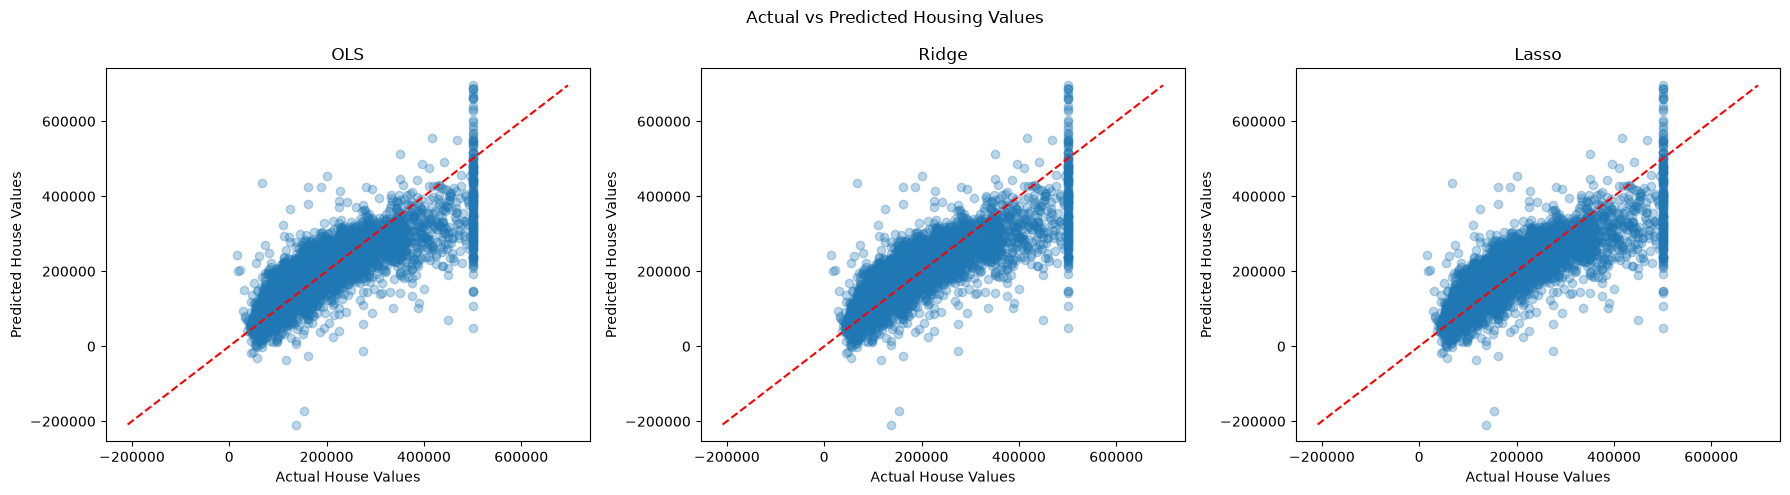

In [24]:
# Compare actual and predicted house values

models = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, (name, predictions) in zip(
    axes,
    models.items()
):

    ax.scatter(
        y_test,
        predictions,
        alpha=0.3
    )

    minimum = min(
        y_test.min(),
        predictions.min()
    )

    maximum = max(
        y_test.max(),
        predictions.max()
    )

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "r--"
    )

    ax.set_title(name)

    ax.set_xlabel("Actual House Values")

    ax.set_ylabel("Predicted House Values")

plt.suptitle(
    "Actual vs Predicted Housing Values"
)

plt.tight_layout()

plt.show()

Residual analysis

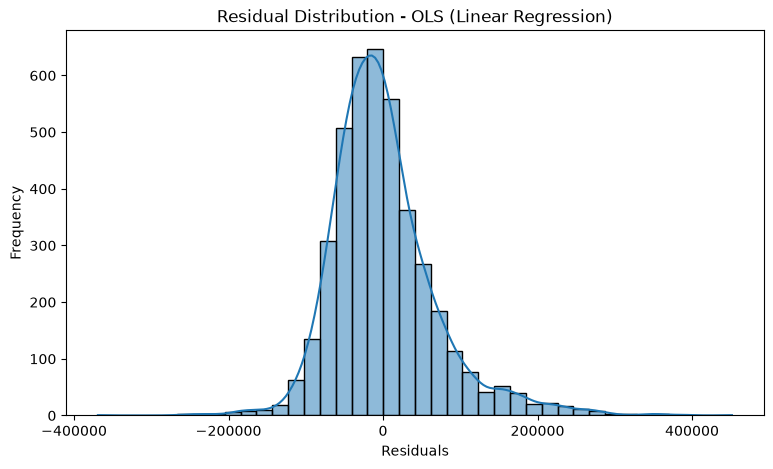

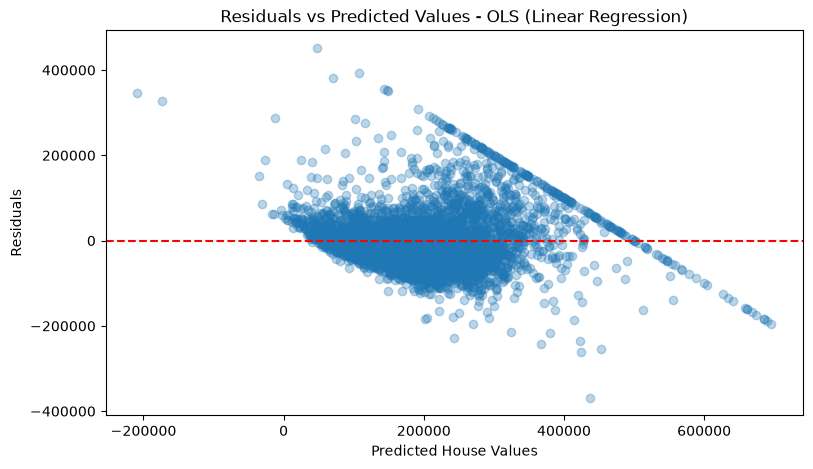

In [25]:
# Select the model with the lowest RMSE

best_index = results_df["RMSE"].idxmin()

best_model_name = results_df.loc[
    best_index,
    "Model"
]

prediction_dictionary = {
    "OLS (Linear Regression)": ols_predictions,
    "Ridge Regression": ridge_predictions,
    "Lasso Regression": lasso_predictions
}

best_predictions = prediction_dictionary[
    best_model_name
]

# Calculate residuals

residuals = y_test - best_predictions


# Residual distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.title(
    f"Residual Distribution - {best_model_name}"
)

plt.xlabel("Residuals")

plt.ylabel("Frequency")

plt.show()


# Residuals vs predicted values

plt.figure(figsize=(9, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title(
    f"Residuals vs Predicted Values - {best_model_name}"
)

plt.xlabel("Predicted House Values")

plt.ylabel("Residuals")

plt.show()

Final conclusion

In [26]:
# Find the best model

best_result = results_df.loc[
    results_df["RMSE"].idxmin()
]

print("TASK 2: FINAL CONCLUSION")
print("================================")

print("Best model:", best_result["Model"])

print("MAE:", round(best_result["MAE"], 2))

print("RMSE:", round(best_result["RMSE"], 2))

print("R2:", round(best_result["R2"], 4))

print("\nPROJECT SUMMARY")

print(
    "Three regression models were developed "
    "to predict California median house values."
)

print(
    "Missing values were handled using median "
    "and most frequent imputation."
)

print(
    "Feature engineering and multicollinearity "
    "analysis were performed."
)

print(
    "Ridge and Lasso hyperparameters were optimized "
    "using GridSearchCV."
)

print(
    f"The best model based on RMSE was {best_result['Model']}."
)

TASK 2: FINAL CONCLUSION
Best model: OLS (Linear Regression)
MAE: 49709.54
RMSE: 68917.32
R2: 0.6375

PROJECT SUMMARY
Three regression models were developed to predict California median house values.
Missing values were handled using median and most frequent imputation.
Feature engineering and multicollinearity analysis were performed.
Ridge and Lasso hyperparameters were optimized using GridSearchCV.
The best model based on RMSE was OLS (Linear Regression).


Test a new housing example

In [27]:
# Create an example new house

new_house = pd.DataFrame([{
    "longitude": -118.25,
    "latitude": 34.05,
    "housing_median_age": 25,
    "total_rooms": 1500,
    "total_bedrooms": 300,
    "population": 1000,
    "households": 400,
    "median_income": 5.0,
    "ocean_proximity": "NEAR OCEAN",

    # Engineered features
    "rooms_per_household": 1500 / 400,
    "bedrooms_per_room": 300 / 1500,
    "population_per_household": 1000 / 400,
    "income_x_rooms": 5.0 * (1500 / 400)
}])

# Select best model

model_dictionary = {
    "OLS (Linear Regression)": ols_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

best_model = model_dictionary[best_model_name]

# Predict

prediction = best_model.predict(new_house)[0]

print("NEW HOUSING PREDICTION")
print("==============================")

print(
    "Estimated median house value: $",
    format(prediction, ",.2f")
)

NEW HOUSING PREDICTION
Estimated median house value: $ 265,674.68
